# Serie di seni e coseni (Fourier) per forme d'onda quadre e triangolari

## Generalità

Una funzione periodica $g(t)$ di periodo $T$ e frequenza angolare $\omega = 2 \pi/T$ può essere approssimata dalla somma di una costante $a_0$, pari al valore medio sul periodo, con una serie troncata di seni e coseni:
$$g(t)=a_0 + \sum_{k=1}^{k=N_{iter}} b_k \cos(\omega_k t) + \sum_{k=1}^{k=N_{iter}} c_k \sin(\omega_k t)\;;$$
i termini $b_k$ e $c_k$ si chiamano **coefficienti di Fourier** e generalmente l'approssimazione migliora al crescere del numero di elementi della somma, $N_{iter} \rightarrow \infty$.

Nel seguito saranno considerate forme d'onda **alternate**, per cui $a_0 = 0$.

I termini seno e coseno si chiamano **armoniche di ordine** $k$ (l'armonica è detta **fondamentale** per $k = 1$):
nel caso delle forme d'onda quadre e triangolari le somme comprendono solo elementi **dispari**, cioè $k = 1, 3, 5, ...$.

## Forma d'onda quadra (dispari)

Senza perdita di generalità, consideriamo una forma d'onda quadra *dispari* di ampiezza unitaria, cioè tale che la sua forma ''analitica'' è
$$g_{anal}(t)= \textrm{sgn} [ \sin(\omega t)]\;,$$
dove $\textrm{sgn}[$ $]$ rappresenta la funzione segno.

Per parità si ha $b_k = 0$ $\forall$ $k$. Inoltre è
$$c_k = \frac{4}{\pi k}\;,$$
dove il fattore 4 serve per ottenere un'ampiezza unitaria.

Il codice qui sotto permette di calcolare la somma troncata, implementata con un banale ciclo for, e di farne il grafico considerando arrays di $N_{pnts}$ punti.

Inoltre esso consente di rilassare la condizione di forma d'onda dispari e tenere conto dell'eventuale termine di fase costante. Per semplicità, invece di considerare l'espressione generica dei coefficienti $b_k$ e $c_k$ (facile, ma un po' laboriosa), il termine di fase costante viene interpretato come un ritardo e inserito direttamente nell'array ancillare dei tempi. Naturalmente è anche possibile rilassare le condizioni di forma d'onda alternata e di ampiezza non unitaria: basta infatti rispettivamente aggiungere un termine di offset costante al risultato della somma e moltiplicare la somma per un termine di ampiezza costante.

Osservate con un po' di attenzione cosa succede al variare di $N_{iter}$ e anche di $N_{pnts}$: le oscillazioni corrispondenti ai fronti di salita e di discesa sono una conseguenza della derivata temporale finita per seni e coseni e infinita per la forma d'onda quadra. Nella matematica delle funzioni (continue, non *discrete* come nella rappresentazione di Python!) tali oscillazioni vengono spesso ascritte al cosiddetto *fenomeno di Gibbs*. Nel nostro caso, oltre al fenomeno di Gibbs abbiamo sicuramente anche effetti dovuti al **campionamento** delle forme d'onda: infatti la rilevanza delle oscillazioni dipende, oltre che dal numero di iterazioni $N_{iter}$ della somma, dalla scelta del numero di punti dell'array, $N_{pnts}$.

Potete anche notare come, in certe condizioni, le oscillazioni sembrino ''non deterministiche'', cioè appaiano diverse in corrispondenza di diversi fronti di salita e discesa: anche questo è un effetto del campionamento (pensateci bene!).

In [24]:
from IPython.display import display, clear_output
import ipywidgets as widgets
import pylab as py
import numpy as np

# valori iniziali dei parametri (utili al primo avvio)
periodi = 4
nofpoints = 500
nofiter = 20
phi = 0

# definisce gli elementi di input
casella_input_1 = widgets.Text(value='500', placeholder='Numero dei punti dell\'array:', description='$N_{pnts}$:')
casella_input_2 = widgets.Text(value='20', placeholder='Numero di iterazioni:', description='$N_{iter}$:')
casella_input_3 = widgets.Text(value='0', placeholder='Fase costante:', description='$\\Phi$ [rad]:')
pulsante = widgets.Button(description='Plot', tooltip='Clicca per far partire l\'iterazione',button_style='success')

# definisce l'area di output e la mostra
area_output = widgets.Output(layout={'border': '1px solid red'})
display(casella_input_1,casella_input_2,casella_input_3,pulsante,area_output)

# definisce le operazioni da compiere alla pressione del pulsante Plot
def click(b):
    with area_output:
        clear_output(wait=True) # pulisce l'area di output in modo da riscriverci sopra
        nofpoints = int(casella_input_1.value) # legge numero di punti dell'array
        nofiter = int(casella_input_2.value) # numero iterazioni
        phi = float(casella_input_3.value) # eventuale fase costante
        delay=np.pi*phi # che viene interpretata come ritardo (essendo la frequenza unitaria)
        tarray = np.linspace(0+delay,periodi+delay,nofpoints) # crea l'array dei tempi (notate come viene trattata la fase)
        somma = tarray*0 # crea l'array che ospiterà la somma
        
        for i in range(1,nofiter,2): # itera a passo due in modo da prendere solo le armoniche dispari
            somma = somma + fouriercoeff(i)*funz(tarray,i)
            
        py.plot(tarray,somma,color='blue') # grafica la somma troncata in blue
        py.plot(tarray,square(tarray),color='red') # e, per riferimento, la forma analitica in rosso
        py.xlabel('Time  [T]')
        py.ylabel('$g(t)$')
        py.legend(['Fourier series','Analytical'],loc='upper right')
        py.show()

# collega il pulsante alla funzione
pulsante.on_click(click)

# calcola i coefficienti di Fourier (forma quadra dispari)
def fouriercoeff(k):
    return 4/(np.pi*k)

# calcola la frequenza angolare
def omegak(k):
    return 2*np.pi*k
 
# questa è la funzione che entra nella somma (forma quadra dispari)
def funz(x,wk):
    return np.sin(x*omegak(wk))

# questa è la funzione forma d'onda quadra ''analitica''
def square(x):
    return np.sign(np.sin(x*omegak(1)))




Text(value='500', description='$N_{pnts}$:', placeholder="Numero dei punti dell'array:")

Text(value='20', description='$N_{iter}$:', placeholder='Numero di iterazioni:')

Text(value='0', description='$\\Phi$ [rad]:', placeholder='Fase costante:')

Button(button_style='success', description='Plot', style=ButtonStyle(), tooltip="Clicca per far partire l'iter…

Output(layout=Layout(border_bottom='1px solid red', border_left='1px solid red', border_right='1px solid red',…

## Forma d'onda triangolare (pari)

Senza perdita di generalità, consideriamo una forma d'onda triangolare *pari* di ampiezza unitaria, cioè tale che la sua forma ''analitica'' è
$$g_{anal}(t)= 1-\frac{2 \arccos[\cos(\omega t)]}{\pi}\;.$$

Per parità si ha $c_k = 0$ $\forall$ $k$. Inoltre è
$$c_k = \frac{8}{(\pi k)^2}\;,$$
dove il fattore 8 serve per ottenere un'ampiezza unitaria e dove si vede che i coefficienti di Fourier tendono a zero per $k \rightarrow \infty$ come $1/k^2$ (l'andamento era come $1/k$ nel caso della forma quadra).

Il codice qui sotto permette di calcolare la somma troncata, implementata con un banale ciclo for, e di farne il grafico considerando arrays di $N_{pnts}$ punti. A parte le debite modifiche, esso ricalca il codice precedente.

Per la forma d'onda triangolari si osserva facilmente come un risultato *qualitativamente* (visivamente) soddisfacente richieda un numero di iterazioni nettamente minore che per la forma quadra. Infatti in questo caso non ci sono derivate temporali divergenti e l'andamento può essere riprodotto più facilmente con la somma di coseni. 

Infine valgono le considerazioni di sopra per quanto riguarda l'eventuale presenza di un termine di fase costante, il carattere eventualmente non alternato, l'ampiezza eventualmente non unitaria.

In [23]:
from IPython.display import display, clear_output
import ipywidgets as widgets
import pylab as py
import numpy as np

# valori iniziali dei parametri (utili al primo avvio)
periodi = 4
nofpoints = 500
nofiter = 8
phi = 0

# definisce gli elementi di input
casella_input_1 = widgets.Text(value='500', placeholder='Numero dei punti dell\'array:', description='$N_{pnts}$:')
casella_input_2 = widgets.Text(value='8', placeholder='Numero di iterazioni:', description='$N_{iter}$:')
casella_input_3 = widgets.Text(value='0', placeholder='Fase costante:', description='$\\Phi$ [rad]:')
pulsante = widgets.Button(description='Plot', tooltip='Clicca per far partire l\'iterazione',button_style='success')

# definisce l'area di output e la mostra
area_output = widgets.Output(layout={'border': '1px solid red'})
display(casella_input_1,casella_input_2,casella_input_3,pulsante,area_output)

# definisce le operazioni da compiere alla pressione del pulsante Plot
def click(b):
    with area_output:
        clear_output(wait=True) # pulisce l'area di output in modo da riscriverci sopra
        nofpoints = int(casella_input_1.value) # legge numero di punti dell'array
        nofiter = int(casella_input_2.value) # numero iterazioni
        phi = float(casella_input_3.value) # eventuale fase costante
        delay=np.pi*phi # che viene interpretata come ritardo (essendo la frequenza unitaria)
        tarray = np.linspace(0+delay,periodi+delay,nofpoints) # crea l'array dei tempi (notate come viene trattata la fase)
        somma = tarray*0 # crea l'array che ospiterà la somma
        
        for i in range(1,nofiter,2): # itera a passo due in modo da prendere solo le armoniche dispari
            somma = somma + fouriercoeff(i)*funz(tarray,i)

        py.plot(tarray,square(tarray),color='red') # grafica, per riferimento, la forma analitica in rosso
        py.plot(tarray,somma,color='blue') # grafica la somma troncata in blue
        py.xlabel('Time  [T]')
        py.ylabel('$g(t)$')
        py.legend(['Fourier series','Analytical'],loc='upper right')
        py.show()

# collega il pulsante alla funzione
pulsante.on_click(click)

# calcola i coefficienti di Fourier (forma triangolare pari)
def fouriercoeff(k):
    return 8/(np.pi*k)**2

# calcola la frequenza angolare
def omegak(k):
    return 2*np.pi*k

# questa è la funzione che entra nella somma (forma triangolare pari)
def funz(x,wk):
    return np.cos(x*omegak(wk))

# questa è la funzione forma d'onda quadra ''analitica''
def square(x):
    return (1-2*np.acos(np.cos(x*omegak(1)))/np.pi)




Text(value='500', description='$N_{pnts}$:', placeholder="Numero dei punti dell'array:")

Text(value='100', description='$N_{iter}$:', placeholder='Numero di iterazioni:')

Text(value='0', description='$\\Phi$ [rad]:', placeholder='Fase costante:')

Button(button_style='success', description='Plot', style=ButtonStyle(), tooltip="Clicca per far partire l'iter…

Output(layout=Layout(border_bottom='1px solid red', border_left='1px solid red', border_right='1px solid red',…

## Una semplice ''animazione''

Il codice qui sotto permette di graficare la serie troncata di Fourier nel caso di una forma d'onda quadra (più interessante) mano a mano che le iterazioni vanno avanti.
Rispetto ai codici precedenti, questo è semplificato all'osso, poiché tutto l'ambaradan potrebbe funzionare male.
Potete provare a vedere come si comporta (e modificarlo, se volete)!

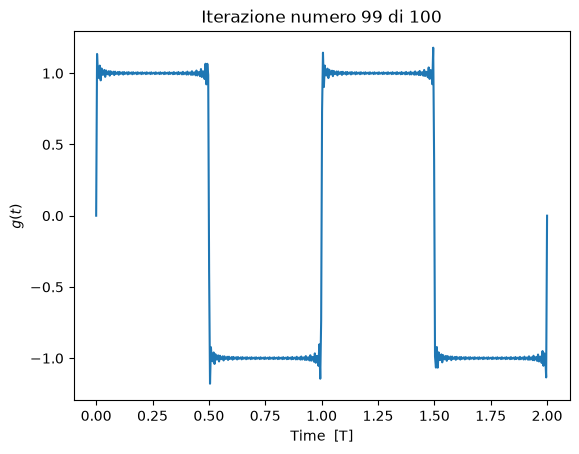

In [3]:
from IPython.display import display, clear_output
import pylab as py
import numpy as np

# valori dei parametri (si possono cambiare, volendo!)
periodi = 2
nofpoints = 500
nofiter = 100 # questo è il numero massimo di iterazioni

# definisce le operazioni da compiere al lancio dello script
tarray = np.linspace(0,periodi,nofpoints) # crea l'array dei tempi
somma = tarray*0 # crea l'array che ospiterà la somma
        
for i in range(1,nofiter,2): # itera a passo due in modo da prendere solo le armoniche dispari
    clear_output(wait=True) # pulisce l'area di output in modo da riscriverci sopra
    somma = somma + (4/(np.pi*i))*np.sin(tarray*2*np.pi*i)            
    py.plot(tarray,somma) # grafica la somma troncata in blue
    py.xlabel('Time  [T]')
    py.ylabel('$g(t)$')
    py.title('Iterazione numero '+str(i)+' di '+str(nofiter)) # scrive nel titolo il numero di iterazione
    if (i<10):
        py.pause(0.2) # introduce un (piccolo) ritardo per i < 10
    if (i<20):
        py.pause(0.02) # che diventa più piccolo per i < 20 
    if (i > 20):
        py.pause(0.002) # e ancora più piccolo dopo (altrimenti non finisce più...)
